# Auction Market Lab — 100-day profit comparison

**Ready for Google Colab.** Upload this notebook through **File → Upload notebook**,
then run its cells from top to bottom. A CPU runtime is sufficient. The project source
is bundled inside this notebook; no separate ZIP upload, Google Drive mount, or API server is needed.

The default experiment uses **six actual competitors**: MACD, price reversal,
volume momentum, sector routing, the orthogonal ensemble, and opponent-aware
expected-profit optimization. Optional benchmarks add three contestants, giving nine.
Changing the roster reruns the auction; it does not merely hide graph lines.

Defaults: 100 evaluation days after 180 warm-up dates; nine synthetic stocks in
three sectors; 1,000,000 initial capital per player; all trading costs zero;
random customer buy/sell requests; every position closed each evening.
Synthetic results are demonstrations, not measured stock-market performance.

Outputs include cumulative and daily profit graphs, a leaderboard and downloadable CSVs.
Source engine: version 0.4.0. The notebook and repository select six or nine
competitors through `Config(competitors=...)`. Forecasts use the latest 126
completed dates within each sector, refitted daily; 180 dates is the initial warm-up.


In [1]:
# @title 1. Restore source and install dependencies
from pathlib import Path
import base64, hashlib, io, json, os, subprocess, sys, tempfile, zipfile

SOURCE_ZIP_BASE64 = '...'
SOURCE_SHA256 = '294acebaa2cda8a1beaca247767022066af5a52c61a3250e53278809e8e73f7a'
source_bytes = base64.b64decode(SOURCE_ZIP_BASE64)
assert hashlib.sha256(source_bytes).hexdigest() == SOURCE_SHA256
base_directory = Path('/content') if Path('/content').exists() else Path.cwd()
WORK_DIR = Path(tempfile.mkdtemp(prefix='auction_colab_', dir=base_directory))
PROJECT_DIR = WORK_DIR / 'source'
PROJECT_DIR.mkdir()
with zipfile.ZipFile(io.BytesIO(source_bytes)) as archive:
    for member in archive.namelist():
        if not (PROJECT_DIR / member).resolve().is_relative_to(PROJECT_DIR.resolve()):
            raise ValueError('Unexpected path in bundled source')
    archive.extractall(PROJECT_DIR)
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '--quiet', '--disable-pip-version-check',
    '-r', str(PROJECT_DIR / 'requirements.txt')
])
# Ensure rerunning setup uses this fresh copy rather than an earlier imported copy.
for module in list(sys.modules):
    if module == 'auction_lab' or module.startswith('auction_lab.'):
        del sys.modules[module]
sys.path.insert(0, str(PROJECT_DIR))
print('Project ready:', PROJECT_DIR)
print('Dependencies installed. Continue to the experiment settings.')

Project ready: <runtime>/source
Dependencies installed. Continue to the experiment settings.


Change settings before running the experiment. Keep **INCLUDE_BENCHMARKS = False**
for the intended six-player game. Set it to True to add no-trade, fixed-spread and
tight-spread quoting. All selected players face the same stocks and customer requests.

The stress scenario and the software checks are optional and off by default.
After changing settings, rerun this cell and every following cell.

In [2]:
# @title 2. Experiment settings
DAYS = 100  # @param {type:"integer"}
WARMUP = 180  # @param {type:"integer"}
SEED = 7  # @param {type:"integer"}
CAPITAL = 1000000.0  # @param {type:"number"}
INCLUDE_BENCHMARKS = False  # @param {type:"boolean"}
RUN_STRESS = False  # @param {type:"boolean"}
RUN_SOFTWARE_TESTS = False  # @param {type:"boolean"}
USE_HISTORICAL_CSV = False  # @param {type:"boolean"}
HISTORICAL_CSV_PATH = ''  # @param {type:"string"}

from auction_lab.signals import CORE_STRATEGIES, STRATEGIES
CORE_PLAYERS = CORE_STRATEGIES
BENCHMARKS = ('no_trade', 'flat_quote', 'tight_quote')
ACTIVE_PLAYERS = STRATEGIES if INCLUDE_BENCHMARKS else CORE_STRATEGIES
print(f'{len(ACTIVE_PLAYERS)} competitors:', ', '.join(ACTIVE_PLAYERS))

6 competitors: macd, price_reversal, volume_momentum, sector_router, orthogonal_ensemble, opponent_aware


For your own historical data, enable **USE_HISTORICAL_CSV** and either supply an
uploaded file path or leave the path empty to open a file picker. Required columns:
`date,symbol,sector,open,close,volume`. Sector names must be `technology`,
`commodities`, or `financials`. Include at least **WARMUP + DAYS** complete dates
for every stock (280 dates with the defaults). The first WARMUP dates provide initial history; the next DAYS dates are evaluated.
Each daily forecaster uses the latest 126 completed dates. Select your desired date range before
uploading. Prepare consistent prices/volumes and account for corporate actions.
The CSV supplies price paths; customer orders and executions remain simulated.

In [3]:
# @title 3. Load data and select the actual auction participants
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import auction_lab
from auction_lab.data import synthetic_data, load_data
from auction_lab.engine import Config, Game
from dataclasses import asdict, replace
from datetime import datetime, timezone

def show_table(frame):
    try:
        from IPython.display import display
    except ImportError:
        print(frame.to_string(index=False))
    else:
        display(frame)

def show_png(path):
    try:
        from IPython.display import display, Image
    except ImportError:
        print('Figure saved:', path)
    else:
        display(Image(filename=str(path)))

if RUN_SOFTWARE_TESTS:
    # Fresh subprocess checks auction rules, both rosters, reports and API.
    subprocess.check_call([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-v'],
                          cwd=PROJECT_DIR)

config = Config(days=DAYS, warmup=WARMUP, seed=SEED, capital=CAPITAL,
                competitors=len(ACTIVE_PLAYERS),
                fee_bps=0, closing_half_spread_bps=0,
                closing_slippage_bps=0, short_borrow_bps=0,
                informed_fraction=0)
if USE_HISTORICAL_CSV:
    csv_path = HISTORICAL_CSV_PATH.strip()
    if not csv_path:
        try:
            from google.colab import files
        except ImportError as exc:
            raise ValueError('Outside Colab, set HISTORICAL_CSV_PATH to a local file.') from exc
        uploaded = files.upload()
        csv_candidates = [name for name in uploaded if name.lower().endswith('.csv')]
        if len(csv_candidates) != 1:
            raise ValueError('Please upload exactly one CSV containing all stocks.')
        csv_path = csv_candidates[0]
    data = load_data(csv_path)
    DATA_LABEL = 'User-supplied historical prices; simulated auctions'
else:
    data = synthetic_data(max(80, WARMUP + DAYS), SEED)
    DATA_LABEL = 'SYNTHETIC demonstration'
OUT = Path(tempfile.mkdtemp(prefix=f'results_{len(ACTIVE_PLAYERS)}players_', dir=WORK_DIR))
data.to_csv(OUT / 'input_prices.csv', index=False)
print(DATA_LABEL)
print(f'{data.symbol.nunique()} stocks, {data.date.nunique()} dates; {DAYS} evaluation days.')
print('Transaction costs: zero for every player.')

SYNTHETIC demonstration
9 stocks, 280 dates; 100 evaluation days.
Transaction costs: zero for every player.


In [4]:
# @title 4. Run the tournament and save results
def run_tournament(game_config, label):
    simulation = Game(data, game_config, data_label=DATA_LABEL)
    assert tuple(simulation.players) == ACTIVE_PLAYERS
    while not simulation.done:
        simulation.step()
        if simulation.index % 20 == 0 or simulation.done:
            print(f'{label}: completed {simulation.index}/{game_config.days} days', flush=True)
    return simulation

def save_tournament(simulation, destination):
    destination.mkdir(parents=True, exist_ok=True)
    frame = pd.DataFrame(simulation.daily)
    assert set(frame.player) == set(ACTIVE_PLAYERS)
    assert (frame.costs == 0).all() and (frame.inventory_end == 0).all()
    for name, rows in [('daily_pnl', simulation.daily), ('trades', simulation.trades),
                       ('quotes', simulation.quote_log), ('customer_orders', simulation.order_log),
                       ('predictions', simulation.prediction_log),
                       ('opponent_decisions', simulation.opponent_decisions)]:
        pd.DataFrame(rows).to_csv(destination / f'{name}.csv', index=False)
    board = simulation.leaderboard()
    board.to_csv(destination / 'leaderboard.csv', index=False)
    daily_profit = frame.pivot(index='date', columns='player', values='net_pnl').sort_index()
    cumulative_profit = daily_profit.cumsum()
    cumulative_profit.to_csv(destination / 'cumulative_profit.csv')
    (100 * cumulative_profit / simulation.config.capital).to_csv(destination / 'cumulative_return_pct.csv')
    from auction_lab.report import clean_json
    summary = {'data_label': DATA_LABEL, 'source_version': auction_lab.__version__,
               'source_sha256': SOURCE_SHA256, 'config': asdict(simulation.config),
               'active_players': list(ACTIVE_PLAYERS), 'number_of_players': len(ACTIVE_PLAYERS),
               'days_completed': simulation.index, 'all_inventory_closed': True,
               'leaderboard': board.to_dict('records'),
               'runtime': {'python': sys.version.split()[0], 'numpy': np.__version__,
                           'pandas': pd.__version__, 'matplotlib': matplotlib.__version__}}
    (destination / 'summary.json').write_text(json.dumps(clean_json(summary), indent=2), encoding='utf-8')
    return board, daily_profit, cumulative_profit

game = run_tournament(config, 'Main tournament')
leaderboard, daily_profit, cumulative_profit = save_tournament(game, OUT)
show_table(leaderboard[['player', 'net_pnl', 'return_pct', 'max_drawdown_cash', 'filled_shares']].round(2))
print(f'Verified: {len(ACTIVE_PLAYERS)} players, zero transaction costs, zero inventory at every close.')

Main tournament: completed 20/100 days
Main tournament: completed 40/100 days
Main tournament: completed 60/100 days
Main tournament: completed 80/100 days
Main tournament: completed 100/100 days
Verified: 6 players, zero transaction costs, zero inventory at every close.


player,net_pnl,return_pct,max_drawdown_cash,filled_shares
sector_router,51060.52,5.11,12302.81,233652
opponent_aware,44693.89,4.47,18160.89,309770
price_reversal,41234.53,4.12,15952.50,266835
volume_momentum,4965.63,0.50,30628.26,263035
orthogonal_ensemble,-357.03,-0.04,33279.23,333569
macd,-10106.59,-1.01,25349.57,266330


The cumulative-profit graph shows
\[
\mathrm{PnL}_i(t)=\sum_{d=1}^{t}\mathrm{daily\ profit}_{i,d}.
\]
Every line begins at zero before trading. A falling line means that strategy lost
money over those days. Values are cash profit, not stock prices or portfolio value;
portfolio value is initial capital plus cumulative profit. Synthetic prices use
arbitrary currency units. Real data must use one consistent currency.

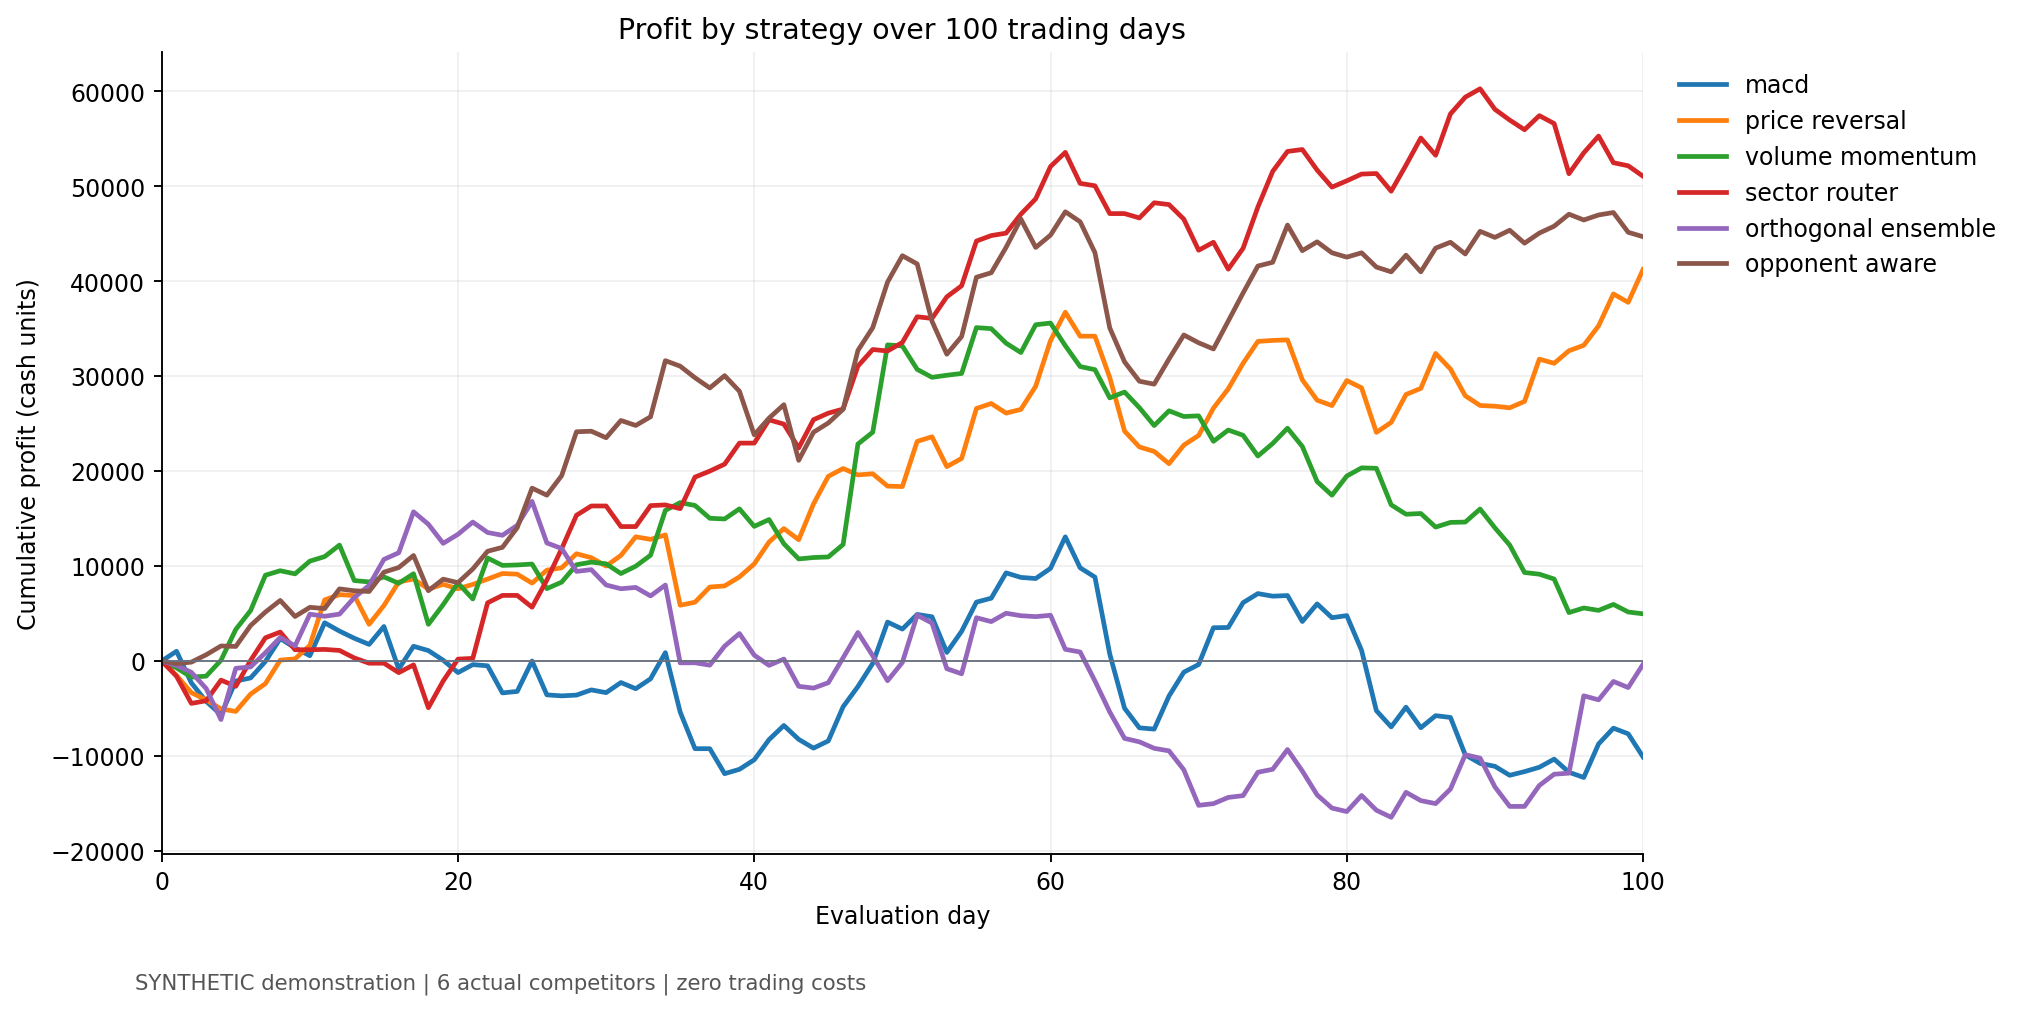

In [5]:
# @title 5. Plot cumulative profit for every strategy
COLORS = dict(zip(ACTIVE_PLAYERS, plt.get_cmap('tab10').colors))
def plot_cumulative(frame, filename, title):
    fig, ax = plt.subplots(figsize=(12, 6))
    days = np.arange(len(frame) + 1)
    for player in ACTIVE_PLAYERS:
        values = np.r_[0.0, frame[player].to_numpy()]
        ax.plot(days, values, linewidth=2, color=COLORS[player], label=player.replace('_', ' '))
    ax.axhline(0, color='#6b7280', linewidth=0.8)
    ax.set(xlabel='Evaluation day', ylabel='Cumulative profit (cash units)',
           title=title, xlim=(0, len(frame)))
    ax.grid(alpha=0.18)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False)
    ax.ticklabel_format(axis='y', style='plain', useOffset=False)
    fig.text(0.07, 0.02, f'{DATA_LABEL} | {len(ACTIVE_PLAYERS)} actual competitors | zero trading costs',
             fontsize=9, color='#555555')
    fig.tight_layout(rect=[0, 0.055, 1, 1])
    fig.savefig(filename, dpi=170, bbox_inches='tight', facecolor='white')
    plt.close(fig)
    show_png(filename)
plot_cumulative(cumulative_profit, OUT / 'cumulative_profit.png',
                f'Profit by strategy over {DAYS} trading days')

Final ranking and overview also saved as overview.png.


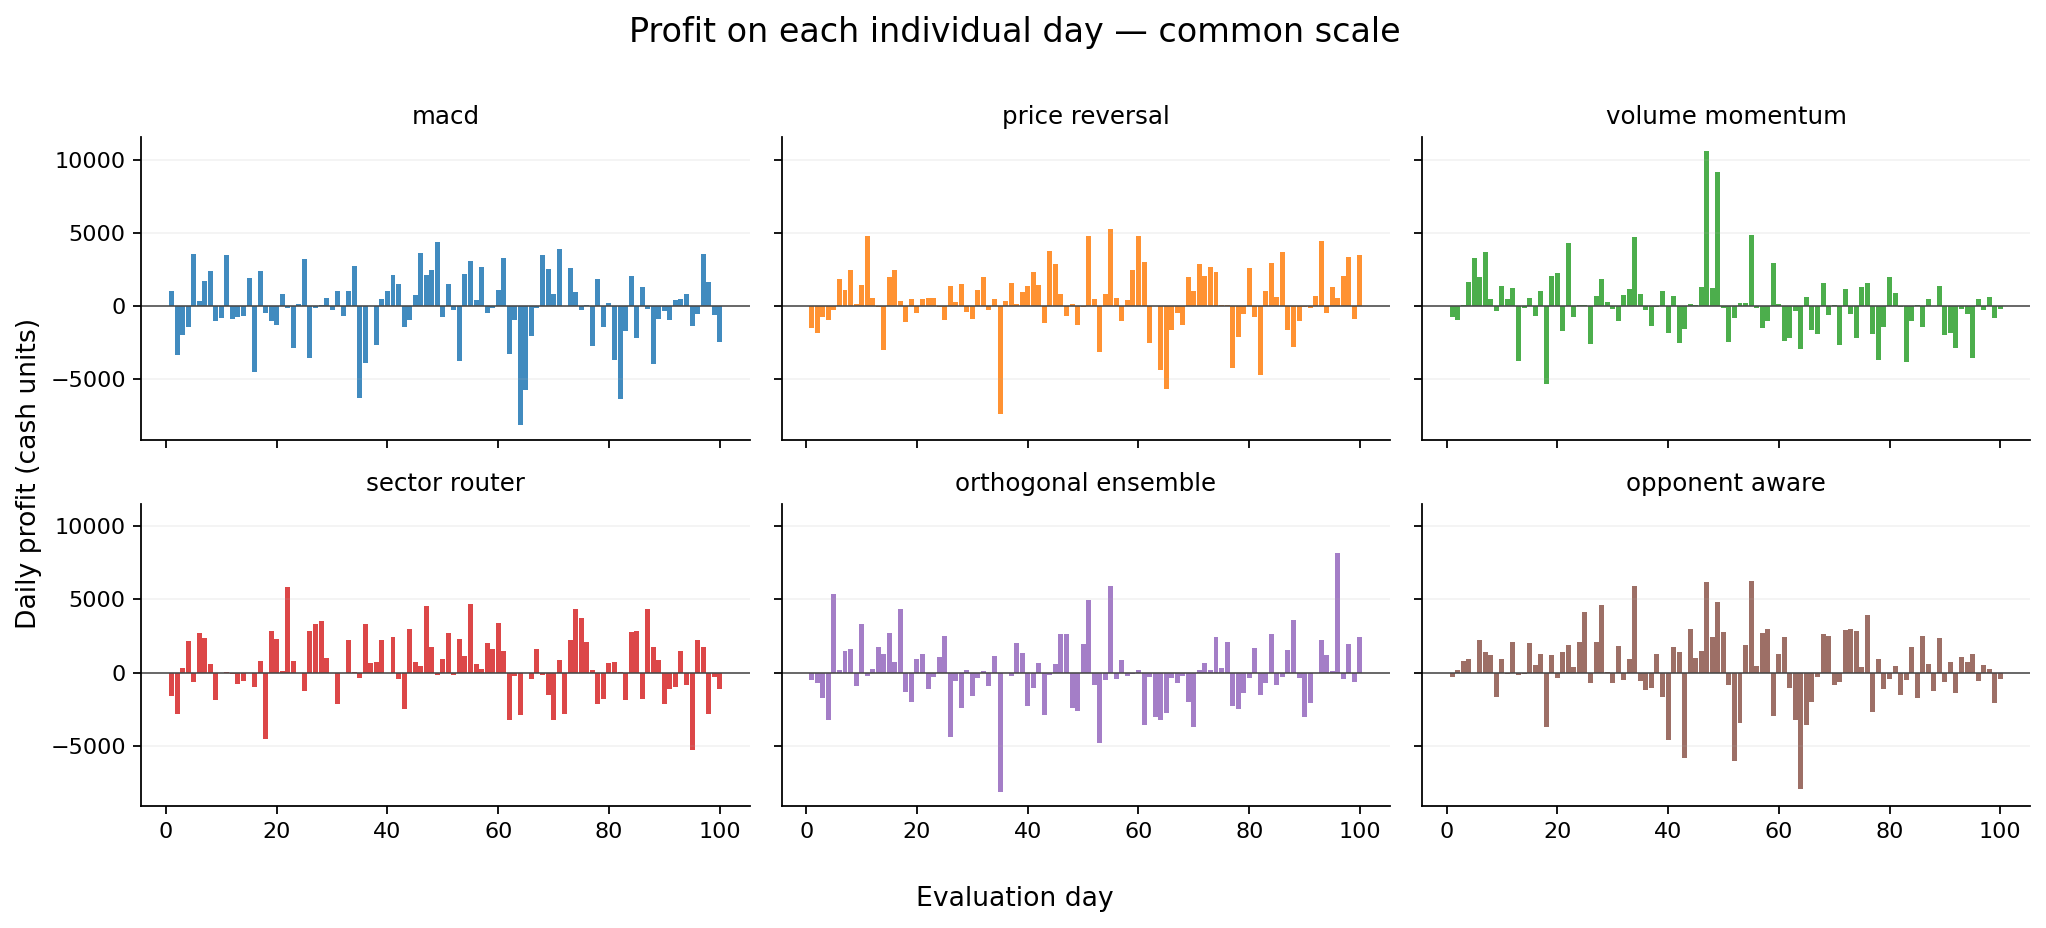

In [6]:
# @title 6. Plot daily profit and final rankings
ncols = 3
nrows = (len(ACTIVE_PLAYERS) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(13, 2.8 * nrows), sharex=True, sharey=True, squeeze=False)
days = np.arange(1, len(daily_profit) + 1)
for ax, player in zip(axes.flat, ACTIVE_PLAYERS):
    ax.bar(days, daily_profit[player], width=0.9, color=COLORS[player], alpha=0.85)
    ax.axhline(0, color='#444444', linewidth=0.7)
    ax.set_title(player.replace('_', ' '), fontsize=11)
    ax.grid(axis='y', alpha=0.15)
    ax.spines[['top', 'right']].set_visible(False)
for ax in list(axes.flat)[len(ACTIVE_PLAYERS):]:
    ax.set_visible(False)
fig.suptitle('Profit on each individual day — common scale', fontsize=15, y=1.01)
fig.supxlabel('Evaluation day')
fig.supylabel('Daily profit (cash units)')
fig.tight_layout()
fig.savefig(OUT / 'daily_profit.png', dpi=160, bbox_inches='tight', facecolor='white')
plt.close(fig)
show_png(OUT / 'daily_profit.png')
from auction_lab.report import plot_game
plot_game(game, OUT / 'overview.png')
print('Final ranking and overview also saved as overview.png.')

Optional stress test: set **RUN_STRESS = True** above, then rerun from settings onward.
Each customer request has a 35% chance of using knowledge of the eventual price
direction; remaining requests have a random side. Dealers never receive the future
closing price before quoting. This uses the same stock prices and random requested
quantities as the main run. It is a deliberately adverse simulation assumption.

In [7]:
# @title 7. Optional informed-customer stress scenario
if RUN_STRESS:
    stress_game = run_tournament(replace(config, informed_fraction=0.35), 'Stress tournament')
    stress_board, stress_daily, stress_cumulative = save_tournament(stress_game, OUT / 'informed_stress')
    plot_cumulative(stress_cumulative, OUT / 'informed_stress' / 'cumulative_profit.png',
                    f'{DAYS}-day stress scenario: 35% informed-request probability')
    comparison = leaderboard[['player', 'net_pnl']].merge(
        stress_board[['player', 'net_pnl']], on='player', suffixes=('_ordinary', '_stress'))
    show_table(comparison.round(2))
else:
    print('Stress scenario skipped. Set RUN_STRESS = True to include it.')

Stress scenario skipped. Set RUN_STRESS = True to include it.


The ZIP below contains graphs, daily and cumulative P&L tables, final rankings,
input prices, auction logs and settings. Download it before disconnecting a Colab
session. Set **DOWNLOAD_RESULTS = True** and run the final cell to download.

Rerun with a different **SEED** to check sensitivity. A result from one 100-day
simulation is not evidence of profitable real-world trading. The six-player results
differ from the previously reported nine-player tournament because competitor
quotes and fills change.

Colab help: https://research.google.com/colaboratory/faq.html

In [8]:
# @title 8. Package and optionally download results
DOWNLOAD_RESULTS = False  # @param {type:"boolean"}
import shutil
results_zip = Path(shutil.make_archive(str(OUT), 'zip', root_dir=OUT))
print('Results ZIP:', results_zip)
print('Graphs: cumulative_profit.png, daily_profit.png, overview.png')
if DOWNLOAD_RESULTS:
    try:
        from google.colab import files
    except ImportError:
        print('Outside Colab, open the ZIP at the path printed above.')
    else:
        files.download(str(results_zip))

Results ZIP: <runtime>/results_6players_v3q9t_tl.zip
Graphs: cumulative_profit.png, daily_profit.png, overview.png
